In [1]:
# Libraries & Data Load

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    KFold,
    RandomizedSearchCV
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [2]:
# Load Dataset

train_df = pd.read_csv(
    "../data/processed/train_feature_engineered.csv"
)

print("Dataset Shape:", train_df.shape)
train_df.head()

Dataset Shape: (1460, 87)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,YrSold,SaleType,SaleCondition,SalePrice,HouseAge,RemodAge,TotalArea,TotalBathrooms,TotalPorchArea,QualityCategory
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,2008,WD,Normal,208500,5,5,2566,3.5,61,Medium
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,2007,WD,Normal,181500,31,31,2524,2.5,298,Medium
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,2008,WD,Normal,223500,7,6,2706,3.5,42,Medium
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,2006,WD,Abnorml,140000,91,36,2473,2.0,307,Medium
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,2008,WD,Normal,250000,8,8,3343,3.5,276,High


In [3]:
# Split Traning & Validation

X = train_df.drop(columns=["SalePrice", "Id"])
y = train_df["SalePrice"]

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Shape:", X_train.shape)
print("Validation Shape:", X_valid.shape)

Training Shape: (1168, 85)
Validation Shape: (292, 85)


In [4]:
# Make Preprocessing Pipline 

numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# Why is this necessary?

When training a model, numerical and categorical data are processed differently. A Pipeline ensures that preprocessing is learned on the training data and the same transformations are applied to the validation data.

In [5]:
# Check Performance Of Baseline Model

baseline_model = joblib.load(
    "../models/random_forest_model.pkl"
)

baseline_predictions = baseline_model.predict(X_valid)

baseline_mae = mean_absolute_error(
    y_valid, baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_valid, baseline_predictions)
)

baseline_r2 = r2_score(
    y_valid, baseline_predictions
)

print("Baseline MAE:", baseline_mae)
print("Baseline RMSE:", baseline_rmse)
print("Baseline R2 Score:", baseline_r2)

Baseline MAE: 17450.09654109589
Baseline RMSE: 29092.80918222806
Baseline R2 Score: 0.8896537743961318


In [6]:
# Use Cross-Validation

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

baseline_cv_scores = cross_val_score(
    baseline_model,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

baseline_cv_rmse = -baseline_cv_scores

print("CV RMSE Scores:", baseline_cv_rmse)
print("Average CV RMSE:", baseline_cv_rmse.mean())
print("Standard Deviation:", baseline_cv_rmse.std())

CV RMSE Scores: [27847.46103488 34491.47876609 35418.06401805 22988.22104472
 23432.35534409]
Average CV RMSE: 28835.516041567775
Standard Deviation: 5285.472716853269


# For MY Understanding: 
n_splits=5: The training data is divided into 5 parts.

Each time, 4 parts are used for training and 1 part is used for validation.

neg_root_mean_squared_error: In Scikit-learn, error scoring is returned in negative form, so we add a - sign to get a positive RMSE.

A lower Average RMSE is better.

A lower Standard Deviation means the performance across different folds is relatively consistent.

In [7]:
# Now we will try to improve performance by changing the model's settings.
# Make New Random Forest Pipeline: 

rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            random_state=42,
            n_jobs=-1
        ))
    ]
)

In [9]:
# Make Parameter Range

param_grid = {
    "model__n_estimators": [100, 200, 300, 500],
    "model__max_depth": [None, 10, 20, 30],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": [0.5, 0.8, 1.0]
}

# Why was model__ used?

Because our Random Forest is a step named "model" inside the Pipeline. To change a parameter of that specific step, we write it as model__parameter_name (with a double underscore).

In [10]:
# Make Randomized Search

random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_grid,
    n_iter=20,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


C:\Users\91726\OneDrive\Desktop\House-Price-Analysis-Prediction\.venv\Lib\site-packages\joblib\externals\loky\process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__max_depth': [None, 10, ...], 'model__max_features': [0.5, 0.8, ...], 'model__min_samples_leaf': [1, 2, ...], 'model__min_samples_split': [2, 5, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maxim

In [11]:
# See Best Parameter And Score 

print("Best Parameters:")
print(random_search.best_params_)

print("\nBest Cross Validation RMSE:")
print(-random_search.best_score_)

Best Parameters:
{'model__n_estimators': 500, 'model__min_samples_split': 2, 'model__min_samples_leaf': 1, 'model__max_features': 1.0, 'model__max_depth': None}

Best Cross Validation RMSE:
28673.81294444907


# Important: Hyperparameter tuning was done only on X_train, y_train. X_valid, y_valid are still kept separate for final evaluation.

In [12]:
# To Check Validation Performance Of Tuned Model.

best_model = random_search.best_estimator_

tuned_predictions = best_model.predict(X_valid)

tuned_mae = mean_absolute_error(
    y_valid, tuned_predictions
)

tuned_rmse = np.sqrt(
    mean_squared_error(y_valid, tuned_predictions)
)

tuned_r2 = r2_score(
    y_valid, tuned_predictions
)

print("Tuned Model MAE:", tuned_mae)
print("Tuned Model RMSE:", tuned_rmse)
print("Tuned Model R2:", tuned_r2)

Tuned Model MAE: 17450.71610958904
Tuned Model RMSE: 29210.417592971397
Tuned Model R2: 0.8887598163483222


In [13]:
# TO Comparission of Tuned Model and Baseline

comparison_df = pd.DataFrame({
    "Model": ["Baseline Random Forest", "Tuned Random Forest"],
    "MAE": [baseline_mae, tuned_mae],
    "RMSE": [baseline_rmse, tuned_rmse],
    "R2 Score": [baseline_r2, tuned_r2]
})

display(comparison_df)

,Model,MAE,RMSE,R2 Score
0,Baseline Random Forest,17450.096541,29092.809182,0.889654
1,Tuned Random Forest,17450.716110,29210.417593,0.888760


# How to understand the result?

Lower MAE = Lower average prediction error.

Lower RMSE = Lower impact of large prediction errors.

Higher R² = The model explains the variation in prices within the validation data better.

In [14]:
from sklearn.inspection import permutation_importance

importance_result = permutation_importance(
    best_model,
    X_valid,
    y_valid,
    n_repeats=10,
    random_state=42,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

In [15]:
# Make The DataFrame of Feature Importance

feature_importance = pd.DataFrame({
    "Feature": X_valid.columns,
    "Importance": importance_result.importances_mean,
    "Importance_STD": importance_result.importances_std
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance.head(15))

,Feature,Importance,Importance_STD
81,TotalArea,35796.375507,2054.081751
16,OverallQual,11273.441523,597.667859
84,QualityCategory,5288.194619,558.293572
43,2ndFlrSF,3260.827859,123.832542
60,GarageCars,1610.991519,245.933774
3,LotArea,961.981858,145.909491
45,GrLivArea,776.587410,112.444211
29,BsmtQual,649.624115,83.614463
82,TotalBathrooms,639.207940,88.721858
52,KitchenQual,618.222182,74.817769


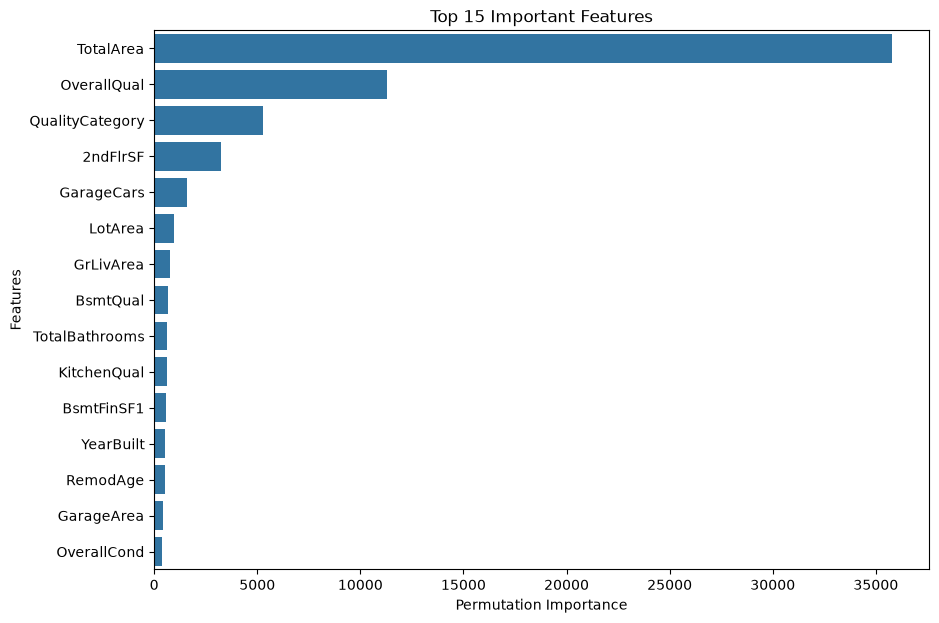

In [16]:
# Top !5 Features of Graph

top_15_features = feature_importance.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_15_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Important Features")
plt.xlabel("Permutation Importance")
plt.ylabel("Features")

plt.show()

# Business Interpretation:

Suppose OverallQual appears most important, then we can write an observation like this:

"House quality is an important predictor of sale price in this model."

Suppose GrLivArea appears important, then:

"Living area provides useful information for estimating residential property prices."

However, you must write the final business insights based on whichever features actually appear at the top in your actual graph.

In [17]:
# Predicition Errors Check

error_analysis = pd.DataFrame({
    "Actual_Price": y_valid,
    "Predicted_Price": tuned_predictions
})

error_analysis["Error"] = (
    error_analysis["Actual_Price"] -
    error_analysis["Predicted_Price"]
)

error_analysis["Absolute_Error"] = (
    error_analysis["Error"].abs()
)

display(
    error_analysis.sort_values(
        by="Absolute_Error",
        ascending=False
    ).head(10)
)

,Actual_Price,Predicted_Price,Error,Absolute_Error
691,755000,574735.772,180264.228,180264.228
898,611657,462470.104,149186.896,149186.896
581,253293,399138.176,-145845.176,145845.176
1046,556581,428515.372,128065.628,128065.628
218,311500,202558.378,108941.622,108941.622
261,276000,380984.664,-104984.664,104984.664
332,284000,375214.090,-91214.090,91214.090
1175,285000,366773.288,-81773.288,81773.288
1243,465000,394617.404,70382.596,70382.596
607,225000,160021.830,64978.170,64978.170


# What will you understand from this?

Error positive: The model predicted a price lower than actual.

Error negative: The model predicted a price higher than actual.

Absolute_Error: How big the difference is between the actual and predicted values.

In [18]:
# Save Tuned Model

joblib.dump(
    best_model,
    "../models/tuned_random_forest_model.pkl"
)

print("Tuned Random Forest Model Saved Successfully!")

Tuned Random Forest Model Saved Successfully!


# Model Improvement & Feature Importance

## Objective
The objective of this stage was to improve the baseline Random Forest model, evaluate its performance, and identify important features influencing house price predictions.

## Activities Performed
1. Loaded the feature-engineered dataset.
2. Created training and validation datasets.
3. Applied preprocessing using Scikit-learn Pipeline.
4. Evaluated the baseline Random Forest model using 5-fold cross-validation.
5. Performed hyperparameter tuning using RandomizedSearchCV.
6. Compared baseline and tuned model performance.
7. Applied Permutation Importance to identify important features.
8. Conducted prediction error analysis.
9. Saved the tuned Random Forest model.

## Evaluation Metrics
- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- R² Score

## Business Value
Feature importance helps understand which property characteristics provide useful information for estimating house prices.

## Output
A tuned Random Forest model, model evaluation results, feature importance analysis, and prediction error analysis.